<a href="https://colab.research.google.com/github/hgshreyas/AI-LAB/blob/main/1BM24CS108_Week9_Resolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


FIRST-ORDER LOGIC : CNF CONVERSION + RESOLUTION THEOREM PROVER
Enter English sentences OR FOL (auto-detected). Examples:
   Alice likes science.            forall x. (likes(x,Science) -> likes(x,Maths))

Number of premises: 5
Premise 1: Everyone who likes science also likes physics or mathematics
Premise 2: Anyone who likes mathematics also likes statistics
Premise 3: Alice likes science
Premise 4: Bob likes physics
Premise 5: If someone likes statistics, then they like data analysis
Statement to prove: Alice likes data analysis

USER INPUT  ->  FIRST-ORDER LOGIC
P1 (input): Everyone who likes science also likes physics or mathematics
     FOL : forall x. (likes(x, Science) -> (likes(x, Physics) | likes(x, Mathematics)))
P2 (input): Anyone who likes mathematics also likes statistics
     FOL : forall x. (likes(x, Mathematics) -> likes(x, Statistics))
P3 (input): Alice likes science
     FOL : likes(Alice, Science)
P4 (input): Bob likes physics
     FOL : likes(Bob, Physics)
P5 (input)

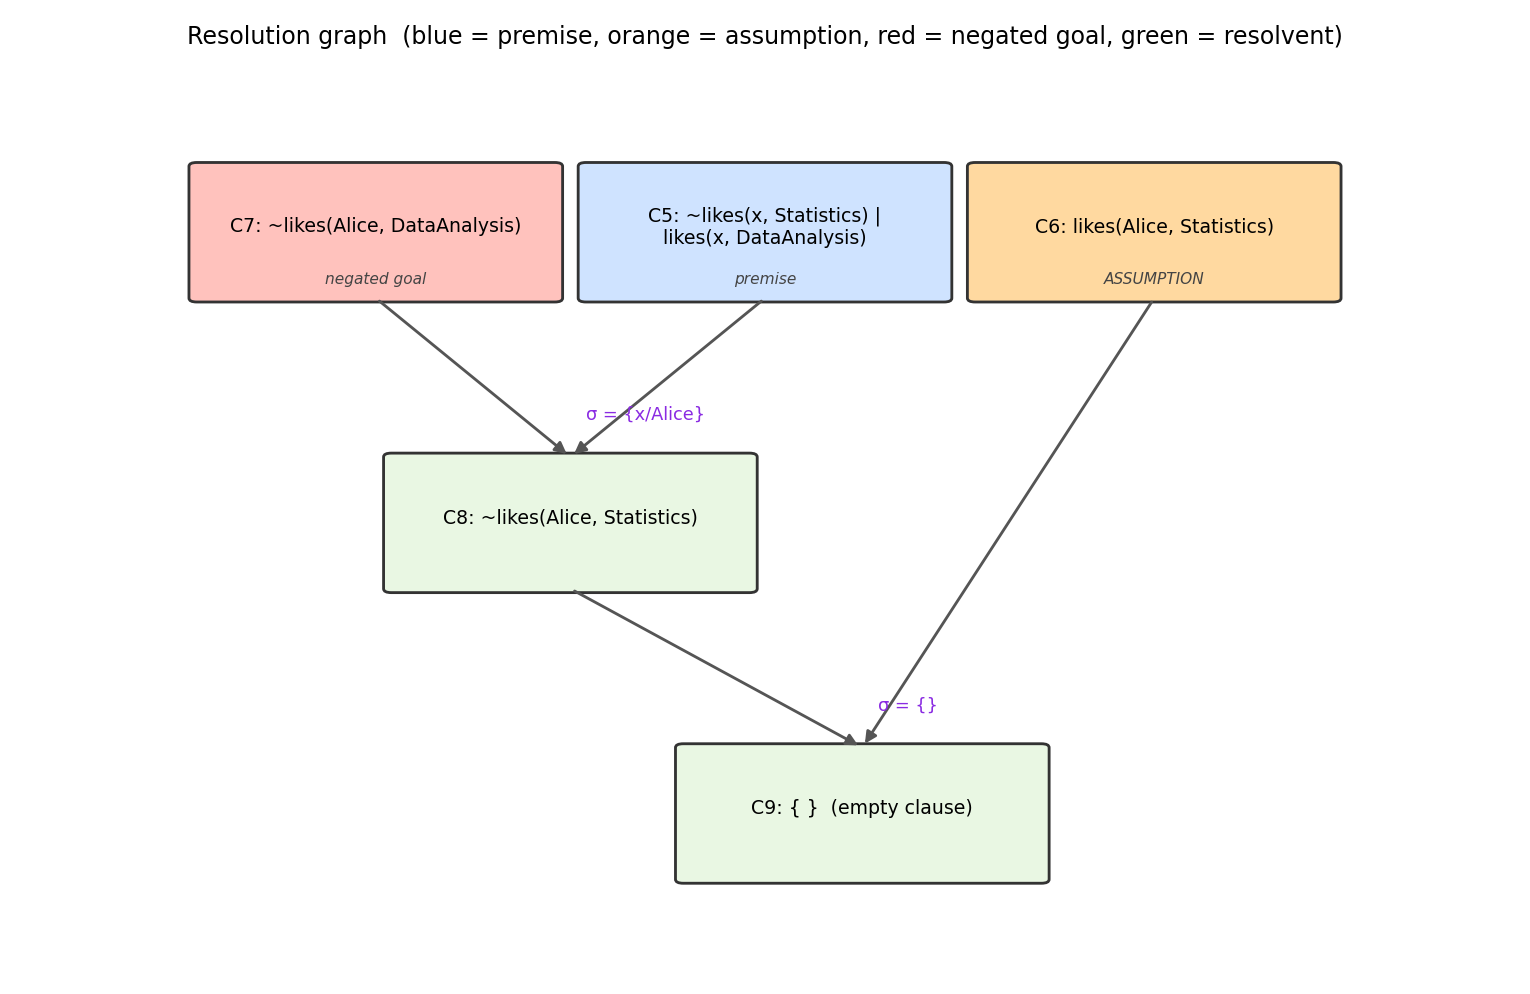

(Graphviz file 'resolution_graph.dot' also written)

FINAL RESULT
PROVED by resolution (empty clause derived).
Goal: likes(Alice, DataAnalysis)

NOTE - the proof only works with these ADDED ASSUMPTIONS (not original premises):
   A1: likes(Alice, Statistics)   =>  likes(Alice, Statistics)


In [1]:
#!/usr/bin/env python3
"""
FOL Resolution Theorem Prover  (English or FOL input, 6-step CNF, resolution graph,
                                Assumption Mode)
--------------------------------------------------------------------------------
Input   : English sentences (template/grammar based) OR first-order logic, auto-detected.
FOL syntax:  forall x. (P(x) -> Q(x))   exists y. R(y)   ~  &  |  ->  <->
Naming   :  variables = lowercase (x, y);  constants = Capitalised (John, Peanuts);
            predicates/functions = any name followed by '('.
Output  : FOL form -> six CNF steps -> negated goal -> resolution with unification
          -> proof graph (tree + edge list + resolution_graph.dot) -> PROVED / NOT PROVED.
If NOT PROVED the program suggests assumptions (missing facts) that make the proof work
and lets you add your own; assumptions are clearly labelled A1, A2, ...
"""
import re
import sys
import itertools
import io
import os
import subprocess
import contextlib
import textwrap
from collections import deque

GRAPH_ONLY = False      # set by  --graph-only  : show only the resolution graph

W = 76


def banner(t):
    print("\n" + "=" * W + "\n" + t + "\n" + "=" * W)


# ============================ 1. FOL PARSER ================================
# term    : str (variable if lowercase-initial, else constant) | ('fn', name, args)
# formula : ('pred',name,args) ('not',f) ('and',a,b) ('or',a,b) ('imp',a,b)
#           ('iff',a,b) ('all',v,f) ('ex',v,f)

def is_var(t):
    return isinstance(t, str) and t[:1].islower()


TOKEN_RE = re.compile(r"<->|->|[()&,|~.]|[A-Za-z_][A-Za-z_0-9]*")


def tokenize(s):
    for a, b in (("¬", "~"), ("∧", "&"), ("∨", "|"), ("↔", "<->"), ("→", "->"),
                 ("∀", " forall "), ("∃", " exists ")):
        s = s.replace(a, b)
    toks = TOKEN_RE.findall(s)
    if "".join(toks) != re.sub(r"\s+", "", s):
        raise ValueError("Unrecognised symbol in FOL expression.")
    return toks


class Parser:
    def __init__(self, text):
        self.t, self.i = tokenize(text), 0

    def peek(self):
        return self.t[self.i] if self.i < len(self.t) else None

    def take(self, exp=None):
        v = self.peek()
        if v is None:
            raise ValueError("Unexpected end of expression.")
        if exp is not None and v != exp:
            raise ValueError(f"Expected '{exp}' but found '{v}'.")
        self.i += 1
        return v

    def parse(self):
        n = self.iff()
        if self.peek() is not None:
            raise ValueError(f"Unexpected token '{self.peek()}'.")
        return n

    def iff(self):
        a = self.imp()
        while self.peek() == "<->":
            self.take()
            a = ("iff", a, self.imp())
        return a

    def imp(self):
        a = self.disj()
        if self.peek() == "->":
            self.take()
            return ("imp", a, self.imp())
        return a

    def disj(self):
        a = self.conj()
        while self.peek() == "|":
            self.take()
            a = ("or", a, self.conj())
        return a

    def conj(self):
        a = self.unary()
        while self.peek() == "&":
            self.take()
            a = ("and", a, self.unary())
        return a

    def unary(self):
        tok = self.peek()
        if tok == "~":
            self.take()
            return ("not", self.unary())
        if tok and tok.lower() in ("forall", "exists"):
            q = "all" if self.take().lower() == "forall" else "ex"
            vs = [self.take()]
            while self.peek() == ",":
                self.take()
                vs.append(self.take())
            if self.peek() == ".":
                self.take()
            for v in vs:
                if not is_var(v):
                    raise ValueError("Quantified variables must start with a lowercase letter.")
            body = self.iff()
            for v in reversed(vs):
                body = (q, v, body)
            return body
        if tok == "(":
            self.take()
            a = self.iff()
            self.take(")")
            return a
        name = self.take()
        if not re.match(r"[A-Za-z_]", name):
            raise ValueError(f"Unexpected token '{name}'.")
        args = ()
        if self.peek() == "(":
            self.take()
            lst = [self.term()]
            while self.peek() == ",":
                self.take()
                lst.append(self.term())
            self.take(")")
            args = tuple(lst)
        return ("pred", name, args)

    def term(self):
        name = self.take()
        if not re.match(r"[A-Za-z_]", name):
            raise ValueError(f"Bad term '{name}'.")
        if self.peek() == "(":
            self.take()
            lst = [self.term()]
            while self.peek() == ",":
                self.take()
                lst.append(self.term())
            self.take(")")
            return ("fn", name, tuple(lst))
        return name


def parse_fol(s):
    return Parser(s).parse()


def tstr(t):
    return t if isinstance(t, str) else t[1] + "(" + ", ".join(tstr(a) for a in t[2]) + ")"


def show(n):
    k = n[0]
    if k == "pred":
        return n[1] + ("(" + ", ".join(tstr(a) for a in n[2]) + ")" if n[2] else "")
    if k == "not":
        return "~" + show(n[1])
    if k in ("all", "ex"):
        b = show(n[2])
        if n[2][0] not in ("pred", "not"):
            b = "(" + b + ")" if not b.startswith("(") else b
        return ("forall " if k == "all" else "exists ") + n[1] + ". " + b
    op = {"and": " & ", "or": " | ", "imp": " -> ", "iff": " <-> "}[k]
    return "(" + show(n[1]) + op + show(n[2]) + ")"


def free_vars(n, bound=frozenset()):
    k = n[0]
    if k == "pred":
        out = []

        def walk(t):
            if isinstance(t, str):
                if is_var(t) and t not in bound and t not in out:
                    out.append(t)
            else:
                for a in t[2]:
                    walk(a)
        for a in n[2]:
            walk(a)
        return out
    if k == "not":
        return free_vars(n[1], bound)
    if k in ("all", "ex"):
        return free_vars(n[2], bound | {n[1]})
    out = free_vars(n[1], bound)
    return out + [v for v in free_vars(n[2], bound) if v not in out]


def close_formula(n):
    """Free variables are treated as universally quantified."""
    for v in reversed(free_vars(n)):
        n = ("all", v, n)
    return n


# ======================= 2. ENGLISH  ->  FOL TRANSLATOR ====================

PREPS = {"with", "from", "to", "in", "on", "at", "of", "for", "about", "by", "into"}
ADV = {"still", "also", "always", "really", "then"}
AUX = {"will", "must", "shall", "can", "would"}
QUANT_SUBJ = {"someone", "somebody", "anyone", "anybody", "everyone", "everybody", "one", "who"}
PRON = {"she", "he", "they", "it"}
VP_START = {"is", "are", "does", "doesn't", "do", "don't", "not", "has", "have",
            "isn't", "aren't"}
DET = {"a", "an", "the", "all", "some", "any", "every", "each"}


class Ctx:
    def __init__(self):
        self.names = ["x", "y", "z", "u", "v", "w"] + [f"x{i}" for i in range(1, 20)]
        self.k = 0
        self.var = None

    def new(self):
        v = self.names[self.k]
        self.k += 1
        return v


def cap(word):
    return word[:1].upper() + word[1:]


def const(text, singular=False):
    words = text.replace("-", " ").split()
    out = []
    for w in words:
        if singular and w[:1].islower() and w.endswith("s") and len(w) > 3 \
                and not w.endswith(("ss", "us", "is", "ics")):
            w = w[:-1]
        out.append(cap(w))
    return "".join(out)


def camel(words):
    ws = [w for w in words if w]
    return ws[0].lower() + "".join(cap(w.lower()) for w in ws[1:])


def singular_noun(w):
    w = w.lower()
    if w.endswith("ies") and len(w) > 4:
        return w[:-3] + "y"
    if w.endswith("s") and not w.endswith(("ss", "us", "is", "ics")) and len(w) > 3:
        return w[:-1]
    return w


def third(v):
    v = v.lower()
    irr = {"have": "has", "do": "does", "go": "goes"}
    if v in irr:
        return irr[v]
    if v.endswith("s") and not v.endswith("ss"):
        return v
    if v.endswith(("ch", "sh", "ss", "x", "z", "o")):
        return v + "es"
    if v.endswith("y") and len(v) > 1 and v[-2] not in "aeiou":
        return v[:-1] + "ies"
    return v + "s"


def P(name, *args):
    return ("pred", name, tuple(args))


def subject_term(word, ctx):
    w = word.lower()
    if w in QUANT_SUBJ or w in PRON:
        if ctx.var is None:
            ctx.var = ctx.new()
        return ctx.var
    return const(word)


def apply_obj(obj, atom, ctx, singular=False):
    o = obj.strip()
    lo = o.lower()
    m = re.match(r"^(?:all kinds? of|all|every|each|any) (.+)$", lo)
    if m:
        y = ctx.new()
        return ("all", y, ("imp", P(camel([singular_noun(m.group(1))]), y), atom(y)))
    m = re.match(r"^(?:an?|some) (.+)$", lo)
    if m:
        y = ctx.new()
        return ("ex", y, ("and", P(camel(m.group(1).split()), y), atom(y)))
    m = re.match(r"^everything(?: that)? (\w+) (\w+)$", o, re.I)
    if m:
        y = ctx.new()
        return ("all", y, ("imp", P(third(m.group(2)), const(m.group(1)), y), atom(y)))
    if lo in ("everything", "everyone"):
        y = ctx.new()
        return ("all", y, atom(y))
    if lo in ("something", "someone"):
        y = ctx.new()
        return ("ex", y, atom(y))
    return atom(const(o, singular))


def vp_head(part):
    toks = part.split()
    for i, tk in enumerate(toks):
        if i > 0 and tk.lower() in PREPS:
            return " ".join(toks[:i + 1]), len(toks) > i + 1
    return toks[0], len(toks) > 1


def is_vp_start(part):
    toks = part.split()
    f = toks[0].lower()
    if f in ADV or f in AUX or f in VP_START:
        return True
    if len(toks) >= 2 and f.endswith("s") and not f.endswith("ss") and f not in DET:
        return True
    return False


def coord(parts, op, subj, ctx):
    first = parts[0]
    head, has_obj = vp_head(first.split(None, 0)[0] and first) if first.split() else ("", False)
    forms = [first]
    for p in parts[1:]:
        if not is_vp_start(p) and has_obj:
            forms.append(head + " " + p)
        else:
            forms.append(p)
    fs = [vp(f, subj, ctx) for f in forms]
    out = fs[0]
    for f in fs[1:]:
        out = (op, out, f)
    return out


def vp(text, subj, ctx):
    toks = text.strip().split()
    while toks and (toks[0].lower() in ADV or toks[0].lower() in AUX):
        toks = toks[1:]
    if not toks:
        raise ValueError("Empty verb phrase.")
    t = " ".join(toks)
    low = t.lower()
    parts = re.split(r"\s+or\s+", t, flags=re.I)
    if len(parts) > 1:
        return coord(parts, "or", subj, ctx)
    parts = re.split(r"\s+and\s+", t, flags=re.I)
    if len(parts) > 1:
        return coord(parts, "and", subj, ctx)
    # negation
    m = re.match(r"^(?:is not|are not|isn't|aren't)\s+(.+)$", t, re.I)
    if m:
        return ("not", vp("is " + m.group(1), subj, ctx))
    m = re.match(r"^(?:does not|doesn't|do not|don't)\s+(.+)$", t, re.I)
    if m:
        return ("not", vp(m.group(1), subj, ctx))
    m = re.match(r"^not\s+(.+)$", t, re.I)
    if m:
        return ("not", vp("is " + m.group(1), subj, ctx))
    # copula
    if toks[0].lower() in ("is", "are"):
        rest = toks[1:]
        if not rest:
            raise ValueError("Incomplete 'is' phrase.")
        if rest[0].lower() in ("a", "an", "the"):
            return P(camel(rest[1:]), subj)
        for k in range(1, len(rest)):
            if rest[k].lower() in PREPS:
                pred = camel(rest[:k + 1])
                obj = " ".join(rest[k + 1:])
                return apply_obj(obj, lambda tm: P(pred, subj, tm), ctx, singular=True)
        return P(camel(rest), subj)
    # ordinary verb phrase
    if len(toks) == 1:
        w = toks[0]
        if w.lower().endswith("s") and not w.lower().endswith("ss"):
            return P(third(w), subj)
        return P(camel([w]), subj)            # bare adjective, e.g.  "alive"
    verb = third(toks[0])
    rest = toks[1:]
    if rest and rest[0].lower() in PREPS:
        verb += cap(rest[0].lower())
        rest = rest[1:]
    if not rest:
        return P(verb, subj)
    return apply_obj(" ".join(rest), lambda tm: P(verb, subj, tm), ctx)


def clause(text, ctx):
    text = text.strip()
    toks = text.split()
    if len(toks) > 1 and toks[0].lower() == "the":
        toks = toks[1:]
    if len(toks) >= 4 and toks[1].lower() == "and":
        a, b, rest = toks[0], toks[2], " ".join(toks[3:])
        return ("and", vp(rest, subject_term(a, ctx), ctx), vp(rest, subject_term(b, ctx), ctx))
    if len(toks) < 2:
        raise ValueError("Sentence too short.")
    return vp(" ".join(toks[1:]), subject_term(toks[0], ctx), ctx)


DELIM = re.compile(r"\s*,?\s+(?:also|implies|then)\s+|\s*,\s*", re.I)


def translate(sentence):
    s = re.sub(r"\s+", " ", sentence.strip()).rstrip(".!").strip()
    s = re.sub(r"\b(she/he|he/she|s/he)\b", "she", s, flags=re.I)
    ctx = Ctx()
    # --- special template (classroom example)
    if re.match(r"^anything (?:anyone|someone|everyone) eats and (?:is )?(?:still )?not killed is food$", s, re.I):
        f = ("all", "x", ("all", "y", ("imp", ("and", P("eats", "x", "y"), ("not", P("killed", "x"))), P("food", "y"))))
        return f
    # --- if A (,) then B
    m = re.match(r"^if (.+?),?\s+then (.+)$", s, re.I)
    if m:
        return close_formula(("imp", clause(m.group(1), ctx), clause(m.group(2), ctx)))
    # --- everyone who A also/implies B
    m = re.match(r"^(?:everyone|everybody|anyone|anybody) (?:who|that) (.+)$", s, re.I)
    if m:
        parts = DELIM.split(m.group(1), maxsplit=1)
        if len(parts) == 2:
            x = ctx.new()
            return ("all", x, ("imp", vp(parts[0], x, ctx), vp(parts[1], x, ctx)))
        raise ValueError("Could not split the 'who ...' clause (use 'also', 'implies' or a comma).")
    m = re.match(r"^(?:everyone|everybody|anyone|anybody) (.+)$", s, re.I)
    if m:
        x = ctx.new()
        return ("all", x, vp(m.group(1), x, ctx))
    m = re.match(r"^(?:all|every|each) (\w+) (?:who|that) (.+)$", s, re.I)
    if m:
        parts = DELIM.split(m.group(2), maxsplit=1)
        if len(parts) == 2:
            x = ctx.new()
            n = P(camel([singular_noun(m.group(1))]), x)
            return ("all", x, ("imp", ("and", n, vp(parts[0], x, ctx)), vp(parts[1], x, ctx)))
        raise ValueError("Could not split the 'who ...' clause.")
    m = re.match(r"^(?:all|every|each) (\w+) (.+)$", s, re.I)
    if m:
        x = ctx.new()
        return ("all", x, ("imp", P(camel([singular_noun(m.group(1))]), x), vp(m.group(2), x, ctx)))
    m = re.match(r"^(?:someone|somebody) (.+)$", s, re.I)
    if m:
        x = ctx.new()
        return ("ex", x, vp(m.group(1), x, ctx))
    m = re.match(r"^some (\w+) (.+)$", s, re.I)
    if m:
        x = ctx.new()
        return ("ex", x, ("and", P(camel([m.group(1)]), x), vp(m.group(2), x, ctx)))
    return close_formula(clause(s, ctx))


def looks_like_fol(s):
    return bool(re.search(r"\b(forall|exists)\b|[∀∃→↔¬∧∨]|->|~|&|\||\b[A-Za-z_]\w*\s*\(", s))


# ========================= 3. CNF CONVERSION (6 STEPS) =====================

def eliminate_implications(n):
    k = n[0]
    if k == "pred":
        return n
    if k == "not":
        return ("not", eliminate_implications(n[1]))
    if k in ("all", "ex"):
        return (k, n[1], eliminate_implications(n[2]))
    a, b = eliminate_implications(n[1]), eliminate_implications(n[2])
    if k == "imp":
        return ("or", ("not", a), b)
    if k == "iff":
        return ("and", ("or", ("not", a), b), ("or", ("not", b), a))
    return (k, a, b)


def to_nnf(n, neg=False):
    k = n[0]
    if k == "not":
        return to_nnf(n[1], not neg)
    if k == "pred":
        return ("not", n) if neg else n
    if k in ("all", "ex"):
        q = ({"all": "ex", "ex": "all"}[k]) if neg else k
        return (q, n[1], to_nnf(n[2], neg))
    op = ({"and": "or", "or": "and"}[k]) if neg else k
    return (op, to_nnf(n[1], neg), to_nnf(n[2], neg))


def tsub(t, m):
    if isinstance(t, str):
        return m.get(t, t) if is_var(t) else t
    return ("fn", t[1], tuple(tsub(a, m) for a in t[2]))


def subst_f(n, m):
    k = n[0]
    if k == "pred":
        return ("pred", n[1], tuple(tsub(a, m) for a in n[2]))
    if k == "not":
        return ("not", subst_f(n[1], m))
    if k in ("all", "ex"):
        m2 = {a: b for a, b in m.items() if a != n[1]}
        return (k, n[1], subst_f(n[2], m2))
    return (k, subst_f(n[1], m), subst_f(n[2], m))


def standardize(n, env=None, used=None):
    env = env or {}
    used = used if used is not None else set()
    k = n[0]
    if k == "pred":
        return subst_f(n, env)
    if k == "not":
        return ("not", standardize(n[1], env, used))
    if k in ("all", "ex"):
        old, new, i = n[1], n[1], 1
        while new in used:
            new = f"{old}{i}"
            i += 1
        used.add(new)
        e2 = dict(env)
        e2[old] = new
        return (k, new, standardize(n[2], e2, used))
    return (k, standardize(n[1], env, used), standardize(n[2], env, used))


def skolemize(n, univ, ctr):
    k = n[0]
    if k == "all":
        return ("all", n[1], skolemize(n[2], univ + [n[1]], ctr))
    if k == "ex":
        name = f"SK{next(ctr)}"
        term = ("fn", name, tuple(univ)) if univ else name
        return skolemize(subst_f(n[2], {n[1]: term}), univ, ctr)
    if k in ("and", "or"):
        return (k, skolemize(n[1], univ, ctr), skolemize(n[2], univ, ctr))
    if k == "not":
        return ("not", skolemize(n[1], univ, ctr))
    return n


def drop_universals(n):
    k = n[0]
    if k == "all":
        return drop_universals(n[2])
    if k in ("and", "or"):
        return (k, drop_universals(n[1]), drop_universals(n[2]))
    if k == "not":
        return ("not", drop_universals(n[1]))
    return n


def distribute(n):
    if n[0] in ("and", "or"):
        a, b = distribute(n[1]), distribute(n[2])
        if n[0] == "or" and a[0] == "and":
            return ("and", distribute(("or", a[1], b)), distribute(("or", a[2], b)))
        if n[0] == "or" and b[0] == "and":
            return ("and", distribute(("or", a, b[1])), distribute(("or", a, b[2])))
        return (n[0], a, b)
    return n


def flatten(n, op):
    return flatten(n[1], op) + flatten(n[2], op) if n[0] == op else [n]


def lit_text(l):
    s, nm, args = l
    return ("" if s else "~") + nm + ("(" + ", ".join(tstr(a) for a in args) + ")" if args else "")


def clause_text(c):
    return " | ".join(lit_text(l) for l in c) if c else "{}  (empty clause)"


def to_clauses(n):
    out = []
    for conj in flatten(n, "and"):
        lits = []
        for lit in flatten(conj, "or"):
            sign = True
            if lit[0] == "not":
                sign, lit = False, lit[1]
            l = (sign, lit[1], lit[2])
            if l not in lits:
                lits.append(l)
        if any((not s, nm, a) in lits for s, nm, a in lits):
            continue                                  # tautology
        out.append(tuple(lits))
    return out


def cnf_six_steps(n, heading, ctr):
    print(f"\n--- CNF conversion: {heading} ---")
    fv = free_vars(n)
    if fv:
        n = close_formula(n)
        print("   (free variables", ", ".join(fv), "treated as universally quantified)")
    print("   Original            :", show(n))
    s1 = eliminate_implications(n)
    print("   Step 1  Eliminate -> and <->      :", show(s1))
    s2 = to_nnf(s1)
    print("   Step 2  Move ~ inward (NNF)       :", show(s2))
    s3 = standardize(s2)
    print("   Step 3  Standardize variables apart:", show(s3))
    s4 = skolemize(s3, [], ctr)
    print("   Step 4  Skolemize (remove exists)  :", show(s4))
    s5 = drop_universals(s4)
    print("   Step 5  Drop universal quantifiers :", show(s5))
    s6 = distribute(s5)
    print("   Step 6  Distribute | over & (CNF)  :", show(s6))
    cl = to_clauses(s6)
    print("   Clauses:")
    for c in cl:
        print("      ", clause_text(c))
    return cl


# ====================== 4. UNIFICATION + RESOLUTION ========================

def walk(t, s):
    while isinstance(t, str) and is_var(t) and t in s:
        t = s[t]
    return t


def occurs(v, t, s):
    t = walk(t, s)
    if t == v:
        return True
    return isinstance(t, tuple) and any(occurs(v, a, s) for a in t[2])


def unify(a, b, s):
    a, b = walk(a, s), walk(b, s)
    if a == b:
        return s
    if is_var(a):
        return None if occurs(a, b, s) else {**s, a: b}
    if is_var(b):
        return None if occurs(b, a, s) else {**s, b: a}
    if isinstance(a, tuple) and isinstance(b, tuple) and a[1] == b[1] and len(a[2]) == len(b[2]):
        for x, y in zip(a[2], b[2]):
            s = unify(x, y, s)
            if s is None:
                return None
        return s
    return None


def full(t, s):
    t = walk(t, s)
    if isinstance(t, tuple):
        return ("fn", t[1], tuple(full(a, s) for a in t[2]))
    return t


def apply_lit(l, s):
    return (l[0], l[1], tuple(full(a, s) for a in l[2]))


def term_vars(t, acc):
    if isinstance(t, str):
        if is_var(t):
            acc.add(t)
    else:
        for a in t[2]:
            term_vars(a, acc)


def clause_vars(c):
    acc = set()
    for l in c:
        for a in l[2]:
            term_vars(a, acc)
    return acc


def depth(t):
    return 0 if isinstance(t, str) else 1 + max([depth(a) for a in t[2]] or [0])


def rename_term(t, m):
    if isinstance(t, str):
        return m.get(t, t) if is_var(t) else t
    return ("fn", t[1], tuple(rename_term(a, m) for a in t[2]))


def rename_clause(c, m):
    return tuple((s, n, tuple(rename_term(a, m) for a in args)) for s, n, args in c)


def rename_apart(c, avoid):
    m, taken = {}, set(avoid)
    for v in sorted(clause_vars(c)):
        nv = v
        while nv in taken:
            nv += "'"
        m[v] = nv
        taken.add(nv)
    return rename_clause(c, m)


VARNAMES = ["x", "y", "z", "u", "v", "w"] + [f"x{i}" for i in range(1, 100)]


def clean(c):
    m = {}
    for l in c:
        acc = []

        def walkv(t):
            if isinstance(t, str):
                if is_var(t) and t not in m and t not in acc:
                    acc.append(t)
            else:
                for a in t[2]:
                    walkv(a)
        for a in l[2]:
            walkv(a)
        for v in acc:
            m[v] = VARNAMES[len(m)]
    return rename_clause(c, m)


def mask(t):
    if is_var(t):
        return "_"
    return t if isinstance(t, str) else ("fn", t[1], tuple(mask(a) for a in t[2]))


def canon(c):
    srt = sorted(c, key=lambda l: repr((l[0], l[1], tuple(mask(a) for a in l[2]))))
    return clean(tuple(srt))


def resolvents(c1, c2):
    c2r = rename_apart(c2, clause_vars(c1))
    out = []
    for i, l1 in enumerate(c1):
        for j, l2 in enumerate(c2r):
            if l1[0] == l2[0] or l1[1] != l2[1] or len(l1[2]) != len(l2[2]):
                continue
            s = {}
            for a, b in zip(l1[2], l2[2]):
                s = unify(a, b, s)
                if s is None:
                    break
            if s is None:
                continue
            lits = []
            for k, l in enumerate(c1):
                if k != i:
                    lits.append(apply_lit(l, s))
            for k, l in enumerate(c2r):
                if k != j:
                    lits.append(apply_lit(l, s))
            uniq = []
            for l in lits:
                if l not in uniq:
                    uniq.append(l)
            if any((not a, b, c) in uniq for a, b, c in uniq):
                continue
            allv = clause_vars(c1) | clause_vars(c2r)
            sd = {v: full(v, s) for v in sorted(allv) if v in s and full(v, s) != v}
            out.append((clean(tuple(uniq)), sd, l1, l2, c2r))
    return out


class Node:
    def __init__(self, clause, kind, label, parents=None, info=None):
        self.clause, self.kind, self.label = clause, kind, label
        self.parents, self.info = parents, info


def run_resolution(inputs, sos, max_derived=2500, max_lits=8, max_depth=3):
    """inputs: list of (label, kind, clause); sos: indices (into inputs) forming the set of support."""
    nodes, seen, remap = [], {}, {}
    for idx, (lab, kind, cl) in enumerate(inputs):
        key = frozenset(canon(cl))
        if key in seen:
            remap[idx] = seen[key]
            continue
        seen[key] = len(nodes)
        remap[idx] = len(nodes)
        nodes.append(Node(cl, kind, lab))
    sos_set = {remap[i] for i in sos}
    for i, nd in enumerate(nodes):
        if not nd.clause:
            return nodes, i
    queue, done = deque(), set()
    for s in sorted(sos_set):
        for o in range(len(nodes)):
            if o != s and frozenset((s, o)) not in done:
                done.add(frozenset((s, o)))
                queue.append((s, o))
    derived = 0
    while queue and derived < max_derived:
        a, b = queue.popleft()
        for res, sd, l1, l2, c2r in resolvents(nodes[a].clause, nodes[b].clause):
            if len(res) > max_lits or any(depth(t) > max_depth for l in res for t in l[2]):
                continue
            key = frozenset(canon(res))
            if key in seen:
                continue
            k = len(nodes)
            seen[key] = k
            nodes.append(Node(res, "derived", "", (a, b), (sd, l1, l2, c2r)))
            derived += 1
            if not res:
                return nodes, k
            for o in range(k):
                pr = frozenset((k, o))
                if pr not in done:
                    done.add(pr)
                    queue.append((k, o))
            if derived >= max_derived:
                break
    return nodes, None


def ancestors(nodes, idx):
    seen, stack = set(), [idx]
    while stack:
        i = stack.pop()
        if i in seen:
            continue
        seen.add(i)
        if nodes[i].parents:
            stack.extend(nodes[i].parents)
    return seen


def sub_text(sd):
    return "{" + ", ".join(f"{k}/{tstr(v)}" for k, v in sd.items()) + "}" if sd else "{}"


def text_graph(nodes, goal_idx, labels, anc):
    """Boxed diagram of the proof drawn with text characters (printed inside the normal output)."""
    longest = max([len(lit_text(l)) for i in anc for l in nodes[i].clause] + [20])
    boxw = max(28, longest + 2 + 4)          # every literal (+ trailing ' |') fits inside a box
    inner = boxw - 4
    L = {}

    def lev(i):
        if i in L:
            return L[i]
        nd = nodes[i]
        if nd.parents:
            dp = [q for q in nd.parents if nodes[q].parents]
            L[i] = 1 + max([lev(q) for q in dp] or [0])
        else:
            L[i] = None
        return L[i]
    for i in anc:
        lev(i)
    children = {}
    for i in anc:
        if nodes[i].parents:
            for q in nodes[i].parents:
                children.setdefault(q, []).append(i)
    for i in anc:
        if L[i] is None:
            L[i] = min(L[c] for c in children[i]) - 1

    def wrap_clause(txt):
        if txt.startswith("{ }"):
            return [txt]
        lits = txt.split(" | ")
        toks = [lit + (" |" if k < len(lits) - 1 else "") for k, lit in enumerate(lits)]
        out, cur = [], ""
        for t in toks:
            cand = t if not cur else cur + " " + t
            if len(cand) <= inner:
                cur = cand
            else:
                out.append(cur)
                cur = t
        out.append(cur)
        return out

    box = {}
    for i in anc:
        nd = nodes[i]
        tag = {"kb": "premise", "assume": "ASSUMPTION", "goal": "negated goal"}.get(nd.kind, "resolvent")
        lines = [f"{labels[i]} ({tag})"]
        lines += wrap_clause("{ }  (empty clause)" if not nd.clause else clause_text(nd.clause))
        if nd.parents:
            lines += textwrap.wrap("σ = " + sub_text(nd.info[0]), inner) or ["σ = {}"]
        box[i] = lines

    xpos = {}

    def size(i, memo={}):
        return 1 if not nodes[i].parents else 1 + sum(size(q) for q in nodes[i].parents)

    def place(i, x):
        if i in xpos:
            return
        xpos[i] = x
        nd = nodes[i]
        if not nd.parents:
            return
        a1, b1 = nd.parents
        if not nodes[a1].parents and not nodes[b1].parents:
            place(a1, x - 0.5)
            place(b1, x + 0.5)
        else:
            main, side = (a1, b1) if (L[a1], size(a1)) >= (L[b1], size(b1)) else (b1, a1)
            place(main, x)
            place(side, x + 1.0)
    place(goal_idx, 0.0)
    maxL = max(L.values())
    for lv in range(0, maxL + 1):          # keep boxes on the same row from overlapping
        row = sorted([i for i in anc if L[i] == lv], key=lambda i: xpos[i])
        last = None
        for i in row:
            if last is not None and xpos[i] < last + 1:
                xpos[i] = last + 1
            last = xpos[i]
    mn = min(xpos.values())
    cx = {i: int(round((xpos[i] - mn) * (boxw + 2))) + boxw // 2 for i in anc}

    lvh = {lv: max(len(box[i]) + 2 for i in anc if L[i] == lv) for lv in range(maxL + 1)}
    top = {0: 0}
    for lv in range(maxL):
        top[lv + 1] = top[lv] + lvh[lv] + 3
    H = top[maxL] + lvh[maxL]
    Wd = max(cx.values()) + boxw // 2 + 2

    U, D, Lf, R = 1, 2, 4, 8
    bits = {}

    def add(x, y, b):
        bits[(x, y)] = bits.get((x, y), 0) | b
    for i in anc:
        nd = nodes[i]
        if not nd.parents:
            continue
        ctop = top[L[i]]
        bus = ctop - 2
        for q in nd.parents:
            pb = top[L[q]] + len(box[q]) + 1
            px, cxx = cx[q], cx[i]
            for y in range(pb + 1, bus):
                add(px, y, U | D)
            if cxx == px:
                add(px, bus, U | D)
            else:
                add(px, bus, U | (R if cxx > px else Lf))
                lo, hi = (px, cxx) if px < cxx else (cxx, px)
                for x in range(lo + 1, hi):
                    add(x, bus, Lf | R)
                add(cxx, bus, D | (Lf if cxx > px else R))
            for y in range(bus + 1, ctop - 1):
                add(cxx, y, U | D)
    chars = {0: " ", U: "│", D: "│", U | D: "│", Lf: "─", R: "─", Lf | R: "─", U | R: "└", U | Lf: "┘",
             D | R: "┌", D | Lf: "┐", U | D | R: "├", U | D | Lf: "┤", Lf | R | U: "┴",
             Lf | R | D: "┬", U | D | Lf | R: "┼"}
    grid = [[" "] * Wd for _ in range(H)]
    for (x, y), b in bits.items():
        if 0 <= y < H and 0 <= x < Wd:
            grid[y][x] = chars.get(b, "┼")
    for i in anc:
        if nodes[i].parents:
            grid[top[L[i]] - 1][cx[i]] = "▼"
    for i in anc:
        left, t = cx[i] - boxw // 2, top[L[i]]
        h = len(box[i]) + 2
        row_txt = ["┌" + "─" * (boxw - 2) + "┐"]
        row_txt += ["│ " + ln.ljust(inner) + " │" for ln in box[i]]
        row_txt += ["└" + "─" * (boxw - 2) + "┘"]
        for k in range(h):
            for c, ch in enumerate(row_txt[k]):
                grid[t + k][left + c] = ch
    return "\n".join("".join(r).rstrip() for r in grid)


def draw_graph_png(nodes, goal_idx, labels, anc, filename="resolution_graph.png"):
    """Draw the proof as a real graph picture (premises on top, empty clause at the bottom)."""
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        from matplotlib.patches import FancyBboxPatch
    except ImportError:
        print("(matplotlib not installed: run 'pip install matplotlib' for the PNG graph;"
              " resolution_graph.dot can be used instead)")
        return None
    level = {}

    def lev(i):
        if i not in level:
            nd = nodes[i]
            level[i] = 0 if not nd.parents else 1 + max(lev(p) for p in nd.parents)
        return level[i]
    for i in anc:
        lev(i)
    # leaf order = depth-first order from the goal, so parents sit near each other
    order, seenl = [], set()

    def dfs(i):
        nd = nodes[i]
        if nd.parents:
            for q in nd.parents:
                dfs(q)
        elif i not in seenl:
            seenl.add(i)
            order.append(i)
    dfs(goal_idx)
    xpos = {i: k * 1.0 for k, i in enumerate(order)}
    maxlev = max(level.values())
    for L in range(1, maxlev + 1):
        row = sorted([i for i in anc if level[i] == L], key=lambda i: sum(xpos[q] for q in nodes[i].parents) / 2)
        last = None
        for i in row:
            x = sum(xpos[q] for q in nodes[i].parents) / 2
            if last is not None and x < last + 1.0:
                x = last + 1.0
            xpos[i] = x
            last = x
    width = max(xpos.values()) - min(xpos.values()) + 1
    fig_w = max(9.0, 2.6 * width)
    fig_h = max(5.0, 1.55 * (maxlev + 1) + 1.2)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    colors = {"kb": "#cfe3ff", "assume": "#ffd9a0", "goal": "#ffc2bd", "derived": "#e9f7e3"}
    pos = {i: (xpos[i], -level[i] * 1.5) for i in anc}
    hw, hh = 0.46, 0.34
    for i in anc:
        nd = nodes[i]
        if nd.parents:
            for q in nd.parents:
                ax.annotate("", xy=(pos[i][0], pos[i][1] + hh), xytext=(pos[q][0], pos[q][1] - hh),
                            arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.2))
            sd = sub_text(nd.info[0])
            ax.text(pos[i][0] + 0.04, pos[i][1] + hh + 0.22, "σ = " + sd, fontsize=7.5,
                    color="#8a2be2", ha="left", va="center")
    for i in anc:
        nd = nodes[i]
        x, y = pos[i]
        ax.add_patch(FancyBboxPatch((x - hw, y - hh), 2 * hw, 2 * hh, boxstyle="round,pad=0.02",
                                    fc=colors[nd.kind], ec="#333", lw=1.2))
        txt = "{ }  (empty clause)" if not nd.clause else clause_text(nd.clause)
        if len(txt) > 26:
            parts, line, out = txt.split(" | "), "", []
            for pt in parts:
                if line and len(line) + len(pt) > 24:
                    out.append(line + " |")
                    line = pt
                else:
                    line = (line + " | " + pt) if line else pt
            out.append(line)
            txt = "\n".join(out)
        tag = {"kb": "premise", "assume": "ASSUMPTION", "goal": "negated goal"}.get(nd.kind, "")
        ax.text(x, y + 0.03, f"{labels[i]}: {txt}", ha="center", va="center", fontsize=8)
        if tag:
            ax.text(x, y - hh + 0.06, tag, ha="center", va="bottom", fontsize=6.5, color="#444", style="italic")
    ax.set_xlim(min(xpos.values()) - 0.9, max(xpos.values()) + 0.9)
    ax.set_ylim(-maxlev * 1.5 - 0.8, 0.9)
    ax.axis("off")
    ax.set_title("Resolution graph  (blue = premise, orange = assumption, red = negated goal, "
                 "green = resolvent)", fontsize=10)
    fig.tight_layout()
    fig.savefig(filename, dpi=170)
    plt.close(fig)
    return filename


def show_image(path):
    """Display the graph picture: inline in Jupyter/Colab, otherwise open the default image viewer."""
    path = os.path.abspath(path)
    print(f"\nGraph picture saved at: {path}")
    try:                                              # Jupyter / Colab / IPython notebook
        from IPython import get_ipython
        ip = get_ipython()
        if ip is not None and type(ip).__name__ != "TerminalInteractiveShell":
            from IPython.display import display, Image
            display(Image(filename=path))
            return
    except Exception:
        pass
    try:                                              # normal desktop: open in the default viewer
        if sys.platform.startswith("win"):
            os.startfile(path)                        # type: ignore[attr-defined]
        elif sys.platform == "darwin":
            subprocess.Popen(["open", path])
        elif os.environ.get("DISPLAY") or os.environ.get("WAYLAND_DISPLAY"):
            subprocess.Popen(["xdg-open", path], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        else:
            return
        print("Opening the graph picture in your image viewer ...")
    except Exception:
        print("(Could not open it automatically - open the file above manually.)")


def print_proof(nodes, goal_idx, n_inputs_printed):
    anc = sorted(ancestors(nodes, goal_idx))
    labels = {}
    nxt = n_inputs_printed + 1
    for i in anc:
        if nodes[i].parents:
            labels[i] = f"C{nxt}"
            nxt += 1
        else:
            labels[i] = nodes[i].label
    if not GRAPH_ONLY:
        banner("RESOLUTION WITH UNIFICATION (only the steps used in the proof)")
    for i in anc:
        nd = nodes[i]
        if not nd.parents or GRAPH_ONLY:
            continue
        sd, l1, l2, c2r = nd.info
        a, b = nd.parents
        print(f"{labels[i]} = Resolve({labels[a]}, {labels[b]})")
        print(f"     {labels[a]:>4}: {clause_text(nodes[a].clause)}")
        print(f"     {labels[b]:>4}: {clause_text(nodes[b].clause)}"
              + ("   [variables renamed: " + clause_text(c2r) + "]" if c2r != nodes[b].clause else ""))
        print(f"     complementary literals: {lit_text(l1)}  and  {lit_text(l2)}")
        print(f"     unifier (substitution): {sub_text(sd)}")
        print(f"     => {clause_text(nd.clause)}")
    banner("RESOLUTION GRAPH  (diagram: premises on top, empty clause at the bottom)")
    print(text_graph(nodes, goal_idx, labels, anc))
    print("\n  [premise / ASSUMPTION / negated goal = input clauses;  resolvent = derived clause;"
          "  σ = unifier used]")
    if not GRAPH_ONLY:
        # ---- tree
        banner("RESOLUTION GRAPH  (tree view: each node is the resolvent of the two nodes below it)")
        shown = set()

        def origin(nd):
            return {"kb": "premise", "assume": "ASSUMPTION", "goal": "negated goal"}.get(nd.kind, "")

        def tree(i, prefix, last, root=False):
            nd = nodes[i]
            conn = "" if root else ("`-- " if last else "|-- ")
            text = f"{labels[i]}: {clause_text(nd.clause)}"
            if not nd.parents:
                text += f"   [{origin(nd)}]"
            else:
                text += f"   [σ = {sub_text(nd.info[0])}]"
            if i in shown and nd.parents:
                print(prefix + conn + f"{labels[i]} (derived above)")
                return
            shown.add(i)
            print(prefix + conn + text)
            if nd.parents:
                kids = nd.parents
                for k, c in enumerate(kids):
                    tree(c, prefix + ("" if root else ("    " if last else "|   ")), k == len(kids) - 1)
        tree(goal_idx, "", True, root=True)
    # ---- edges
    if not GRAPH_ONLY:
        banner("RESOLUTION GRAPH  (edge list)")
        for i in anc:
            nd = nodes[i]
            if nd.parents:
                a, b = nd.parents
                print(f"  {labels[a]}  ──┐")
                print(f"  {labels[b]}  ──┴──[σ={sub_text(nd.info[0])}]──> {labels[i]}: {clause_text(nd.clause)}")
    png = draw_graph_png(nodes, goal_idx, labels, anc)
    if png:
        show_image(png)
    # ---- DOT
    try:
        with open("resolution_graph.dot", "w", encoding="utf-8") as f:
            f.write("digraph Resolution {\n  rankdir=BT;\n  node [shape=box, fontname=Helvetica];\n")
            for i in anc:
                nd = nodes[i]
                txt = clause_text(nd.clause).replace('"', "'")
                col = {"kb": "lightblue", "assume": "orange", "goal": "salmon"}.get(nd.kind, "white")
                f.write(f'  "{labels[i]}" [label="{labels[i]}\\n{txt}", style=filled, fillcolor={col}];\n')
            for i in anc:
                nd = nodes[i]
                if nd.parents:
                    for p in nd.parents:
                        f.write(f'  "{labels[p]}" -> "{labels[i]}" [label="{sub_text(nd.info[0])}"];\n')
            f.write("}\n")
        if not GRAPH_ONLY:
            print("(Graphviz file 'resolution_graph.dot' also written)")
    except OSError:
        pass


# ======================= 5. ASSUMPTION SUGGESTIONS =========================

def suggest_assumptions(inputs, goal_idx_list, limit_candidates=700):
    preds, consts = {}, set()
    for _, _, cl in inputs:
        for s, nm, args in cl:
            preds[nm] = len(args)

            def walkc(t):
                if isinstance(t, str):
                    if not is_var(t):
                        consts.add(t)
                else:
                    for a in t[2]:
                        walkc(a)
            for a in args:
                walkc(a)
    goal_lits = {(l[0], l[1], l[2]) for gi in goal_idx_list for l in inputs[gi][2]}
    cands = []
    for nm, ar in sorted(preds.items()):
        if ar > 2:
            continue
        for tup in itertools.product(sorted(consts), repeat=ar):
            for sign in (True, False):
                cands.append((sign, nm, tuple(tup)))
    cands = cands[:limit_candidates]
    found = []
    for cand in cands:
        if (not cand[0], cand[1], cand[2]) in goal_lits:
            continue                                      # that would just assume the goal itself
        if any(cl == (cand,) for _, _, cl in inputs):
            continue
        trial = inputs + [("A?", "assume", (cand,))]
        nodes, e = run_resolution(trial, goal_idx_list, max_derived=120)
        if e is None:
            continue
        # reject assumptions that are inconsistent with the KB
        kb_only = [x for k, x in enumerate(trial) if k not in goal_idx_list]
        _, e2 = run_resolution(kb_only, [len(kb_only) - 1], max_derived=120)
        if e2 is not None:
            continue
        steps = sum(1 for i in ancestors(nodes, e) if nodes[i].parents)
        found.append((steps, 0 if cand[0] else 1, cand))
    found.sort(key=lambda t: (t[1], t[0]))
    return [c for _, _, c in found[:6]]


# ================================ 6. MAIN ==================================

def ask(prompt):
    try:
        return input(prompt).strip()
    except EOFError:
        return ""


def to_formula(raw, what):
    """Returns (ast, fol_text). English is auto-detected; falls back to manual FOL entry."""
    while True:
        try:
            if looks_like_fol(raw):
                return parse_fol(raw)
            return translate(raw)
        except ValueError as e:
            print(f"   ! Could not understand {what}: {e}")
            raw = ask("   Enter this statement directly in FOL (or press Enter to skip): ")
            if not raw:
                return None


def main():
    global GRAPH_ONLY
    GRAPH_ONLY = "--graph-only" in sys.argv
    banner("FIRST-ORDER LOGIC : CNF CONVERSION + RESOLUTION THEOREM PROVER")
    print("Enter English sentences OR FOL (auto-detected). Examples:")
    print("   Alice likes science.            forall x. (likes(x,Science) -> likes(x,Maths))")
    try:
        n = int(ask("\nNumber of premises: "))
    except ValueError:
        print("Please enter a number.")
        return
    premises = []
    for i in range(n):
        raw = ask(f"Premise {i + 1}: ")
        f = to_formula(raw, f"premise {i + 1}")
        if f is not None:
            premises.append((raw, f))
    raw_goal = ask("Statement to prove: ")
    goal = to_formula(raw_goal, "the goal")
    if goal is None:
        print("No goal given.")
        return

    quiet = contextlib.redirect_stdout(io.StringIO()) if GRAPH_ONLY else contextlib.nullcontext()
    ctr = itertools.count(1)
    inputs = []                      # (label, kind, clause)
    with quiet:
        banner("USER INPUT  ->  FIRST-ORDER LOGIC")
        for i, (raw, f) in enumerate(premises, 1):
            print(f"P{i} (input): {raw}\n     FOL : {show(close_formula(f))}")
        print(f"Goal (input): {raw_goal}\n     FOL : {show(close_formula(goal))}")

        banner("STEPS 1-6 : CONVERT EACH PREMISE TO CNF")
        for i, (_, f) in enumerate(premises, 1):
            for c in cnf_six_steps(f, f"Premise P{i}", ctr):
                inputs.append((f"C{len(inputs) + 1}", "kb", c))

        banner("NEGATE THE GOAL  and  CONVERT TO CNF")
        neg = ("not", close_formula(goal))
        print("Negated goal:", show(neg))
        goal_cl = cnf_six_steps(neg, "Negated goal", ctr)
        for c in goal_cl:
            inputs.append((f"C{len(inputs) + 1}", "goal", c))

    assumptions = []

    def attempt():
        if not GRAPH_ONLY:
            banner("INITIAL CLAUSE SET  (premises + assumptions + negated goal)")
            for lab, kind, c in inputs:
                tag = {"kb": "premise", "assume": "ASSUMPTION", "goal": "negated goal"}[kind]
                print(f"{lab:>4}: {clause_text(c):<60} [{tag}]")
        sos = [k for k, (_, kd, _) in enumerate(inputs) if kd == "goal"]
        nodes, e = run_resolution(inputs, sos)
        if e is not None:
            print_proof(nodes, e, len(inputs))
        return e is not None, sos

    proved, sos = attempt()
    while not proved:
        banner("RESULT: NOT PROVED from the given premises")
        print("Resolution saturated without deriving the empty clause, so the goal does not")
        print("follow from the premises as stated - some fact is missing.")
        if ask("\nAdd an assumption so that it can be proved? (y/n): ").lower() not in ("y", "yes"):
            break
        print("\nSearching for missing facts that would complete the proof ...")
        sug = suggest_assumptions(inputs, sos)
        if sug:
            print("Suggested assumptions (each one makes the goal provable and is consistent with the KB):")
            for k, c in enumerate(sug, 1):
                print(f"   [{k}] {lit_text(c)}")
        else:
            print("No single-fact assumption was found automatically.")
        raw = ask("Pick a number, or type your own assumption (English or FOL), Enter to cancel: ")
        if not raw:
            break
        if raw.isdigit() and 1 <= int(raw) <= len(sug):
            new_cl = [(sug[int(raw) - 1],)]
            fol_txt = lit_text(sug[int(raw) - 1])
            print(f"\nAssumption A{len(assumptions) + 1}: {fol_txt}")
        else:
            f = to_formula(raw, "the assumption")
            if f is None:
                continue
            fol_txt = show(close_formula(f))
            print(f"\nAssumption A{len(assumptions) + 1} (input): {raw}\n     FOL : {fol_txt}")
            with quiet:
                new_cl = cnf_six_steps(f, f"Assumption A{len(assumptions) + 1}", ctr)
        assumptions.append((raw, fol_txt))
        # keep negated goal clauses last, assumptions go before them
        goal_items = [x for x in inputs if x[1] == "goal"]
        rest = [x for x in inputs if x[1] != "goal"]
        for c in new_cl:
            rest.append(("", "assume", c))
        inputs[:] = rest + goal_items
        for k, (lab, kind, c) in enumerate(inputs):
            inputs[k] = (f"C{k + 1}", kind, c)
        proved, sos = attempt()

    banner("FINAL RESULT")
    if proved:
        print("PROVED by resolution (empty clause derived).")
        print("Goal:", show(close_formula(goal)))
        if assumptions:
            print("\nNOTE - the proof only works with these ADDED ASSUMPTIONS (not original premises):")
            for k, (raw, fol_txt) in enumerate(assumptions, 1):
                print(f"   A{k}: {raw if not raw.isdigit() else fol_txt}   =>  {fol_txt}")
    else:
        print("NOT PROVED.  (The goal does not follow from the supplied premises.)")


if __name__ == "__main__":
    main()
